# Obstacle robustness — figure & table generator

Regenerates the obstacle-robustness charts from `results/obstacle_robustness/<model>/summary.json` (produced by `scripts/evaluation/obstacle_robustness_eval.py`). ADAPTED-rate = obstacle robustness. Saves PDFs to `notebooks/Figures/obstacle_robustness/`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import json, glob
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
from rich import print as rich_print
from rich.table import Table

GROUP='obstacle_robustness'
RES=os.path.join(env_utils.DEFAULT_RESULTS_DIR,'obstacle_robustness')
LEVELS=['aligned','easy','hard']
VERDICTS=['ADAPTED','SUCCUMBED','BROKEN','UNPARSED']
# load every model summary
S={}
for p in sorted(glob.glob(os.path.join(RES,'*','summary.json'))):
    m=os.path.basename(os.path.dirname(p)); S[m]=json.load(open(p))
# order models by hard-ADAPTED (desc); core model first if present
def hard(m): return S[m]['by_level']['hard']['adapted'] or 0
MODELS=sorted(S, key=hard, reverse=True)
CORE='Qwen2.5-Coder-32B-Instruct'
print(f'{len(S)} models:', MODELS)

7 models: ['Olmo-3.1-32B-Instruct', 'Qwen2.5-Coder-32B-Instruct', 'Qwen2.5-72B-Instruct', 'GLM-4-32B-0414', 'Qwen2.5-32B-Instruct', 'Qwen2.5-Coder-14B-Instruct', 'Olmo-3.1-32B-Instruct-SFT']


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/obstacle_robustness/obstacle_robustness_overview.pdf


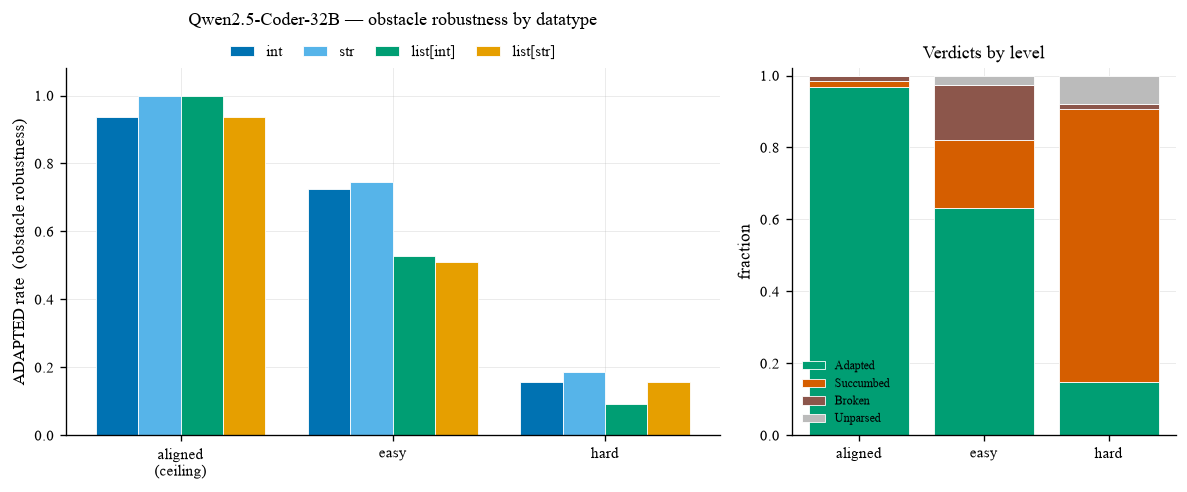

In [2]:
# Coder-32B only: ADAPTED rate by level x datatype (+ verdict breakdown). All-model comparison -> .tex table.
CORE='Qwen2.5-Coder-32B-Instruct'; d=S[CORE]
DTS=['int','str','list[int]','list[str]']
dcol={'int':'#0072B2','str':'#56B4E9','list[int]':'#009E73','list[str]':'#E69F00'}
fig,(axA,axB)=plt.subplots(1,2,figsize=(10,4.2),gridspec_kw=dict(width_ratios=[1.7,1]))
x=np.arange(len(LEVELS)); w=0.8/len(DTS)
for i,dt in enumerate(DTS):
    vals=[(d['by_level'][lv]['by_datatype'].get(dt) or 0) for lv in LEVELS]
    axA.bar(x+i*w-0.4+w/2, vals, w, label=dt, color=dcol[dt], edgecolor='white', linewidth=0.5)
axA.set_xticks(x); axA.set_xticklabels([l+('\n(ceiling)' if l=='aligned' else '') for l in LEVELS])
axA.set_ylabel('ADAPTED rate  (obstacle robustness)'); axA.set_ylim(0,1.08)
axA.set_title('Qwen2.5-Coder-32B — obstacle robustness by datatype')
F.legend_top(axA)
# Panel B: verdict breakdown by level (Coder-32B)
VC={'ADAPTED':'#009E73','SUCCUMBED':'#D55E00','BROKEN':'#8C564B','UNPARSED':'#BBBBBB'}
bottom=np.zeros(len(LEVELS))
for v in ['ADAPTED','SUCCUMBED','BROKEN','UNPARSED']:
    vals=[(d['by_level'][lv]['verdicts'].get(v) or 0) for lv in LEVELS]
    axB.bar(LEVELS, vals, bottom=bottom, label=v.title(), color=VC[v], edgecolor='white', linewidth=0.5)
    bottom+=np.array(vals)
axB.set_ylim(0,1.02); axB.set_ylabel('fraction'); axB.set_title('Verdicts by level')
axB.legend(fontsize=7, frameon=False, loc='lower left')
fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,'obstacle_robustness_overview')); plt.show()

         ADAPTED rate by obstacle level (per model)         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━┳━━━━━━┳━━━━━┓
┃ model                      ┃ aligned ┃ easy ┃ hard ┃   n ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━╇━━━━━━╇━━━━━┩
│ Olmo-3.1-32B-Instruct      │    0.94 │ 0.57 │ 0.21 │ 409 │
│ Qwen2.5-Coder-32B-Instruct │    0.97 │ 0.63 │ 0.15 │ 409 │
│ Qwen2.5-72B-Instruct       │    0.94 │ 0.57 │ 0.12 │ 409 │
│ GLM-4-32B-0414             │    0.91 │ 0.54 │ 0.12 │ 409 │
│ Qwen2.5-32B-Instruct       │    0.97 │ 0.66 │ 0.12 │ 409 │
│ Qwen2.5-Coder-14B-Instruct │    0.91 │ 0.50 │ 0.09 │ 409 │
│ Olmo-3.1-32B-Instruct-SFT  │    0.89 │ 0.35 │ 0.08 │ 409 │
└────────────────────────────┴─────────┴──────┴──────┴─────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/obstacle_robustness/obstacle_adapted_by_level.tex


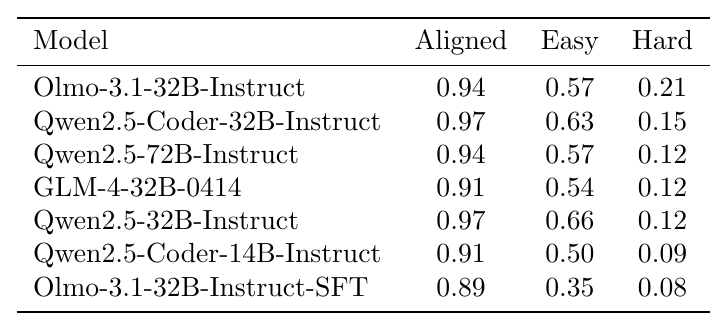

In [3]:
# ── table: ADAPTED rate by level x model (+ emit .tex) ──
t=Table(title='ADAPTED rate by obstacle level (per model)')
t.add_column('model'); [t.add_column(l, justify='right') for l in LEVELS]; t.add_column('n', justify='right')
for m in MODELS:
    t.add_row(m, *[f"{S[m]['by_level'][lv]['adapted'] or 0:.2f}" for lv in LEVELS], str(S[m]['n']))
rich_print(t)

rows=' \\\\\n'.join(m.replace('_','\\_')+' & '+' & '.join(f"{S[m]['by_level'][lv]['adapted'] or 0:.2f}" for lv in LEVELS) for m in MODELS)
tex=('\\begin{tabular}{lccc}\n\\toprule\nModel & Aligned & Easy & Hard \\\\\n\\midrule\n'
     + rows + ' \\\\\n\\bottomrule\n\\end{tabular}')
path=F.save_table(tex, GROUP, 'obstacle_adapted_by_level'); print('wrote', path)
img=F.render_latex_table(tex)
img if img is not None else rich_print('[dim](latex preview unavailable; see rich table above)[/dim]')